# 🚀 Sprint 2: Exploratory Data Analysis (EDA) & Data Cleaning

Cześć Wszytkim. Zrozumienie danych to fundament dobrego Machine Learningu - model uczy się tylko tego, co mu podacie.

Ten notatnik jest podzielony na etapy. Każdy etap ma część **BASIC** (absolutne minimum dla każdego) oraz sekcję **PRO** (dla zespołów, które chcą wycisnąć z danych trochę więcej lub mają już doświadczenie).

**Dlaczego to robimy w Jupyterze, a nie od razu w `train.py`?**
W Jupyterze pracujemy interaktywnie. Możemy wyświetlać tabelki, rysować wykresy i natychmiast widzieć efekty naszych transformacji. `train.py` to z kolei skrypt automatyzujący – wrzucimy tam naszą docelową logikę, kiedy będziemy już dokładnie wiedzieć, czego chcemy.

In [1]:
# Importujemy nasz podstawowy arsenał
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ustawiamy przyjemny dla oka styl wykresów
sns.set_theme(style="whitegrid", palette="muted")
# Wyłączamy ostrzeżenia, żeby notatnik był czystszy (opcjonalnie)
import warnings
warnings.filterwarnings('ignore')

## Krok 1: Wczytanie i pierwsze spojrzenie 👀

Zanim zaczniemy cokolwiek modelować, musimy zrozumieć, z czym w ogóle mamy do czynienia. Czy nasze liczby wczytały się poprawnie, czy jako tekst? Ile rzędów mamy do dyspozycji?

**Dlaczego to ważne?** Jeśli kolumna "Cena" zostanie wczytana jako typ obiektowy (tekst), żaden algorytm matematyczny nie będzie w stanie na niej pracować. Należy to od razu wyłapać używając `info()`.

In [3]:
# Zmieńcie poniższą ścieżkę na Wasz właściwy dataset z folderu data/raw/
# W tym przykładzie generujemy mały zbiór danych dla celów demonstracyjnych
np.random.seed(42)
df = pd.DataFrame({
    'metraz': np.random.normal(50, 15, 1000),
    'liczba_pokoi': np.random.choice([1, 2, 3, 4], 1000),
    'rok_budowy': np.random.choice([1980, 1995, 2010, 2022, np.nan], 1000),
    'dzielnica': np.random.choice(['Jeżyce', 'Rataje', 'Piątkowo', np.nan], 1000),
    'cena': np.random.normal(400000, 100000, 1000)
})

# Celowe wprowadzenie brudu, żeby symulować błędy z prawdziwego świata
df.loc[0, 'cena'] = 50000000 # Potężna anomalia
df.loc[1, 'metraz'] = -10 # Ujemny metraż

# Jak to wygląda na żywo?
display(df.head())

# Sprawdzamy typy i braki. Typ 'object' oznacza najczęściej tekst.
print("\n=== INFO O DANYCH ===")
df.info()

# Szybki przegląd statystyk - tutaj szukamy wspomnianych wyżej ujemnych wartości czy ogromnych outlierów.
display(df.describe())

,metraz,liczba_pokoi,rok_budowy,dzielnica,cena
0,57.450712,3,2010.0,Piątkowo,5.000000e+07
1,-10.000000,4,1980.0,Piątkowo,3.859072e+05
2,59.715328,1,NaN,Rataje,4.316540e+05
3,72.845448,4,2010.0,Rataje,4.189661e+05
4,46.487699,3,2010.0,Rataje,2.394535e+05



=== INFO O DANYCH ===
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   metraz        1000 non-null   float64
 1   liczba_pokoi  1000 non-null   int64  
 2   rok_budowy    798 non-null    float64
 3   dzielnica     1000 non-null   str    
 4   cena          1000 non-null   float64
dtypes: float64(3), int64(1), str(1)
memory usage: 39.2 KB


,metraz,liczba_pokoi,rok_budowy,cena
count,1000.000000,1000.000000,798.000000,1.000000e+03
mean,50.232055,2.473000,2002.481203,4.497279e+05
std,14.811277,1.128958,15.984906,1.571549e+06
min,-10.000000,1.000000,1980.000000,6.752443e+04
25%,40.236770,1.000000,1995.000000,3.313655e+05
50%,50.379509,2.000000,2010.000000,3.986263e+05
75%,59.719158,4.000000,2022.000000,4.692666e+05
max,107.790972,4.000000,2022.000000,5.000000e+07


## Krok 2: Zrozumienie rozkładów i szukanie korelacji 📊

Zrozumienie kształtu danych pomaga w doborze narzędzi i algorytmów.

*   **BASIC:** Analiza zmiennej docelowej (Target Variable) to podstawa. Jeśli przewidujecie cenę (która zazwyczaj jest skośna), a ma "długi ogon" w prawo, modele liniowe będą mieć problemy z dokładnym przewidywaniem najdroższych mieszkań.
*   **PRO:** Macierz korelacji jest kluczowa. Dlaczego? Jeśli dwie cechy, np. `liczba_pokoi` i `metraz`, są ze sobą niemal w 100% skorelowane (obie rosną jednocześnie), wnoszą tę samą informację. Modele liniowe "głupieją" przy takich danych (zjawisko współliniowości), więc jedną z nich często warto usunąć. Korelacja ze zmienną docelową z kolei pokazuje, z czego model będzie najchętniej czerpał wiedzę.

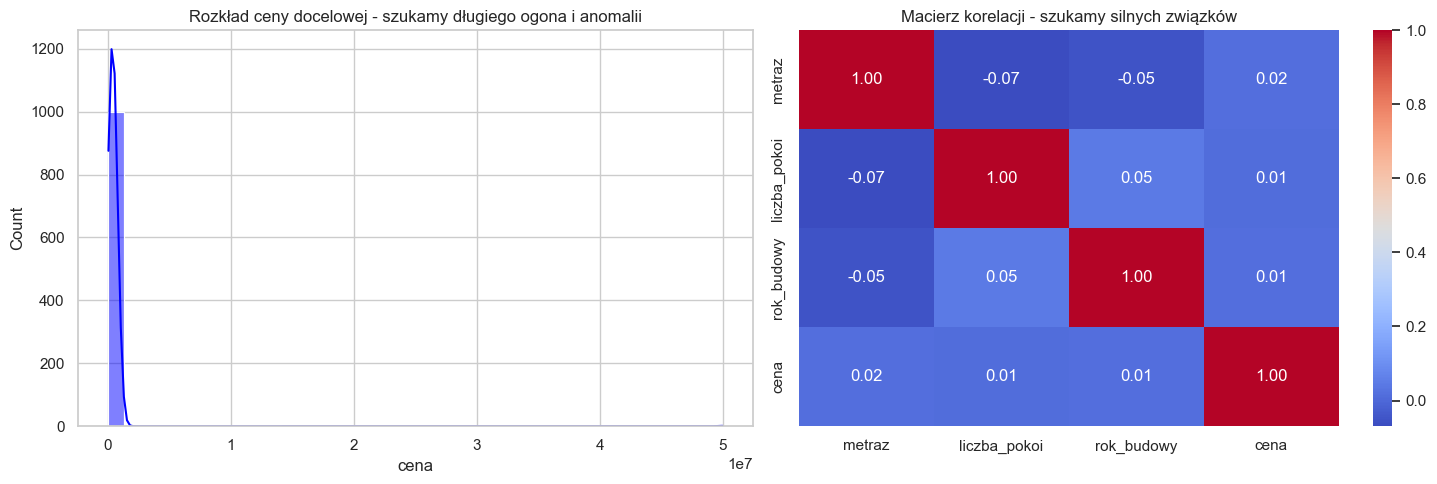

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# --- BASIC: Rozkład zmiennej docelowej ---
sns.histplot(df['cena'], bins=40, kde=True, ax=axes[0], color='blue')
axes[0].set_title('Rozkład ceny docelowej - szukamy długiego ogona i anomalii')

# --- PRO: Macierz korelacji Pearsona (dla cech ciągłych/numerycznych) ---
# Szukamy korelacji bliskich 1 lub -1.
corr_matrix = df.select_dtypes(include=[np.number]).corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", ax=axes[1])
axes[1].set_title('Macierz korelacji - szukamy silnych związków')

plt.tight_layout()
plt.show()

# Na podstawie wykresu ceny widzimy absurdalną wartość. Wyczyśćmy ją na szybko:
df = df[df['cena'] < 10000000]
df = df[df['metraz'] > 0]

## Krok 3: Radzenie sobie z brakami i brudem (Data Cleaning) 🧹

Prawdziwe dane zawsze mają dziury, np. braki informacji o roku budowy, błędne pomiary z czujników itp. Nie możemy puścić pustego wiersza (tzw. `NaN`) do modelu, bo rzuci on nam błędem i zatrzyma obliczenia.

*   **BASIC:** Uzupełniamy luki prostą logiką. Dla zmiennych numerycznych stosujemy medianę, bo średnia mogłaby zostać zaburzona jednym ogromnym domem, który zawyżyłby całą średnią. Wtedy małym kawalerkom bez znanego metrażu wstawilibyśmy np. 150m2, co pogorszy predykcję. Dla tekstów, uzupełniamy jako np. "Nieznana", żeby model traktował ten "brak" jako odrębną kategorię z własnym zachowaniem.
*   **PRO:** Zaawansowane uzupełnianie braków. Zamiast wpisywać sztywną medianę wszędzie, dlaczego nie użyć uczenia maszynowego do zgadywania braków? `KNNImputer` bada inne kolumny – na przykład, szuka 5 najbardziej podobnych mieszkań (np. pod kątem liczby pokoi i metrażu) i wpisuje średni rok budowy właśnie z tych konkretnych 5 sąsiadów, co jest znacznie precyzyjniejsze niż przypisanie globalnej mediany.

In [5]:
# Ograniczmy nasz zbiór, żeby wyświetlić proste podsumowanie
print("Braki przed czyszczeniem:")
print(df.isnull().sum())

# --- BASIC: Ręczne łatanie za pomocą strategii stałych ---
df_basic = df.copy()
# Wszystkie NaN dla tekstowych zamieniamy na nową kategorie
df_basic['dzielnica'] = df_basic['dzielnica'].fillna('Nieznana')
# Wszystkie NaN dla numerycznych zastępujemy globalną medianą z całego zbioru
df_basic['rok_budowy'] = df_basic['rok_budowy'].fillna(df_basic['rok_budowy'].median())

# --- PRO: Zaawansowana Imputacja metodą Najbliższych Sąsiadów ---
from sklearn.impute import KNNImputer

df_pro = df.copy()
# Modele oparte na odległości (KNN) potrzebują tylko liczb.
num_cols = ['metraz', 'liczba_pokoi', 'rok_budowy']
# Inicjalizujemy model, mówiąc mu: poszukaj 5 najbliższych mieszkań i z nich wyciągnij średnią.
knn = KNNImputer(n_neighbors=5)
# Uczymy model i od razu uzupełniamy braki w kolumnie rok_budowy na podstawie 'metraz' i 'liczba_pokoi'
df_pro[num_cols] = knn.fit_transform(df_pro[num_cols])

print("\nBraki po czyszczeniu (Basic):")
print(df_basic.isnull().sum())

Braki przed czyszczeniem:
metraz            0
liczba_pokoi      0
rok_budowy      202
dzielnica         0
cena              0
dtype: int64

Braki po czyszczeniu (Basic):
metraz          0
liczba_pokoi    0
rok_budowy      0
dzielnica       0
cena            0
dtype: int64


## Krok 4: Inżynieria Cech (Feature Engineering) 🧠

Zwykłe modele nie wyciągną wniosków z samej daty urodzenia czy surowego tekstu. To od nas zależy, czy zaserwujemy im informacje w strawnej formie.

Dlaczego `cena_za_m2` jest tak ważna? Ponieważ w modelu liniowym `Cena = w1 * Metraz + w2 * Pokoje`, algorytm czasem musi się mocno natrudzić, aby odnaleźć ukrytą regułę wartości m2 dla konkretnej dzielnicy. Dając mu tę cechę na tacy, ułatwiacie mu proces optymalizacji wagi i znacząco poprawiacie dokładność.

In [6]:
current_year = 2026
df_basic = df_basic.copy() # Pracujemy dalej na uzupełnionych danych

# 1. Obliczenia na datach: model znacznie łatwiej przyswoi liniową wartość "Wiek", niż konkretne daty w formacie YYYY.
df_basic['wiek_budynku'] = current_year - df_basic['rok_budowy']

# 2. Tworzenie ważnych zależności matematycznych:
# Pomaga to zniwelować skrajności (np. małe luksusowe vs ogromne zaniedbane).
df_basic['cena_za_m2'] = df_basic['cena'] / df_basic['metraz']

# 3. PRO: Binning (Kategoryzacja numeryczna - tzw. dyskretyzacja)
# Po co to robić? Modele oparte na drzewach decyzyjnych uwielbiają sztywne granice.
# Jeśli dodamy kolumnę definiującą typ mieszkania, model np. szybciej zrozumie "charakter premium" Apartamentu.
df_basic['wielkosc_mieszkania'] = pd.cut(
    df_basic['metraz'],
    bins=[0, 35, 60, 100, np.inf],
    labels=['Kawalerka', 'Średnie', 'Duże', 'Apartament']
)

display(df_basic[['metraz', 'wielkosc_mieszkania', 'wiek_budynku', 'cena_za_m2']].head())

,metraz,wielkosc_mieszkania,wiek_budynku,cena_za_m2
2,59.715328,Średnie,16.0,7228.529870
3,72.845448,Duże,16.0,5751.438149
4,46.487699,Średnie,16.0,5150.900006
5,46.487946,Średnie,46.0,7660.037456
6,73.688192,Duże,16.0,7704.711920


## Krok 5: Most do Produkcji (Scikit-Learn Pipelines) 🚨🚀

W notebooku używaliśmy wcześniej `df.fillna()` (uzupełnianie) czy ewentualnie moglibyśmy użyć `pd.get_dummies()` (zamiana tekstów w macierz zero-jedynkową, np. `Jeżyce=1`, `Rataje=0`).

**Dlaczego to nie działa w `train.py` i we wdrożonej aplikacji webowej?**
Kiedy Wasza apka oparta o Streamlit zacznie działać produkcyjnie, przyjmie zapytanie od konkretnego użytkownika – wycenę pojedynczego mieszkania (np. 1 wiersz danych: `[50m2, Rataje, 2010]`).
W tym wierszu jest tylko dzielnica "Rataje". Jeśli spróbujecie użyć na nim pandasa `pd.get_dummies()`, zapyta on: *Jakie "Jeżyce"? Jakie "Piątkowo"? Ja widzę tylko Rataje*. Wygeneruje zatem tylko jedną nową kolumnę, `dzielnica_Rataje`.
A Wasz model podczas treningu wyuczył się na np. 30 różnych dzielnicach. Kiedy dostanie wycenę z zaledwie jedną nową kolumną, wywali błąd z informacją o niezgodności rozmiaru wejścia (shape mismatch).

**Rozwiązaniem jest `Pipeline` z `ColumnTransformer`.**
Dzięki niemu, obiekt Scikit-Learn przejdzie przez Wasze dane treningowe, zapisze w swojej "pamięci" listę wszystkich 30 dzielnic i idealną medianę z tych danych. Kiedy przekażemy mu potem ten pojedynczy wiersz usera, uzupełni brak idealną medianą z treningu, a ze słowa "Rataje" wygeneruje pełny wektor 30 kolumn, stawiając 1 pod Ratajami i 0 pod 29 pozostałymi zapamiętanymi dzielnicami. Skrypt w `train.py` na końcu spakuje go do `.joblib`!

Zdefiniujmy kompletny proces czyszczenia i transformacji:

In [7]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.base import BaseEstimator, TransformerMixin

# --- PRO: Custom Transformer ---
# Co zrobić z nowymi cechami jak "wiek"? Nie użyjemy df['wiek'],
# musimy kazać pipeline'owi obliczyć to samemu na surowych wprowadzanych danych.
class AgeCalculator(BaseEstimator, TransformerMixin):
    def __init__(self, current_year=2026):
        self.current_year = current_year

    def fit(self, X, y=None):
        return self # Nic nie "trenujemy" matematycznie, ten węzeł to tylko kalkulator

    def transform(self, X):
        X_copy = X.copy()
        # Zastępujemy wartość roku na wiek.
        # (Wymaga przekazania tej cechy do Pipeline'u w oddzielnym kanale).
        X_copy[:, 0] = self.current_year - X_copy[:, 0]
        return X_copy

# --- DEFINIOWANIE POTOKÓW (BASIC + PRO) ---
numeric_features = ['metraz', 'liczba_pokoi']
year_feature = ['rok_budowy'] # Oddzielamy tę kolumnę, aby puścić ją specjalną ścieżką z AgeCalculator
categorical_features = ['dzielnica']

# 1. Pipeline dla cech numerycznych:
# Krok 1: Wstaw zapamiętaną z treningu medianę w miejsce braków.
# Krok 2: StandardScaler - skompresuj ogromne rozstrzały (np. milionowe ceny) do małych przedziałów blisko zera. Algorytmy uczą się na takich liczbach dużo szybciej i nie faworyzują wielkich liczb.
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# 2. Pipeline dla ścieżki obliczeń (nasz niestandardowy kalkulator):
year_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('age_calc', AgeCalculator()),
    ('scaler', StandardScaler())
])

# 3. Pipeline dla cech tekstowych (kategorycznych):
# Krok 1: Puste miejsca na "Nieznane"
# Krok 2: OneHotEncoder - Rozkłada jedną kolumnę 'dzielnica' na wiele kolumn logicznych. Opcja `handle_unknown='ignore'` chroni aplikację, gdy w Streamlicie użytkownik wpisze nową dzielnicę spoza listy treningowej - po prostu da same 0.
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='Nieznane')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Wrzucamy wszystko do jednego głównego węzła!
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('year', year_transformer, year_feature),
        ('cat', categorical_transformer, categorical_features)
    ])

# Bierzemy oryginalne, jeszcze nie obrobione dane (tak jak przyjdą od użytkownika/z bazy)
X = df[['metraz', 'liczba_pokoi', 'rok_budowy', 'dzielnica']]
# Magia się dzieje tutaj:
X_transformed = preprocessor.fit_transform(X)

print("Dane przetworzone i gotowe dla włożenia do maszyny uczącej. Kształt (wiersze, zdekodowane kolumny):")
print(X_transformed.shape)

Dane przetworzone i gotowe dla włożenia do maszyny uczącej. Kształt (wiersze, zdekodowane kolumny):
(998, 7)


### Co dalej?

Na bazie tego notatnika przeglądacie Wasze datasety. Odkrywacie powiązania i ustalacie, które kolumny chcecie zachować.
Kiedy zdecydujecie, co z nimi zrobić, kod potoku z kroku 5 przeniesiemy do docelowego pliku `src/train.py`, dodamy do niego silnik uczenia maszynowego (np. `RandomForestRegressor`) i... Wasza aplikacja będzie gotowa przyjmować Wasze dane.